In [1]:
source('../../../R/preamble.R')

freqplot = function(df, spacing = 0.00){
    ggplot(df) + aes(gen, freq + spacing*dense_rank(pos), col = pos, group = tid) + 
    geom_line() + geom_point(size = 0.3) +
    #scale_x_continuous(breaks = 0:16) +
    facet_wrap(~pop, ncol = 4) +
    labs(x = 'Generation', y = 'Frequency')
    }

fpop = function(n = 5) facet_wrap(~pop, ncol = n)

conf = 0.95

In [2]:
d = read.tsv('../../../datasets/genomics/05_genome_mapping/results/d_aff.tsv')
tid_to_mutator_bg = read.tsv('../../../datasets/genomics/06_mutators/results/tid_to_mutator_bg.tsv')
v = read.tsv('../../../datasets/genomics/04_gene_attribution/results/v.tsv') %>% left_join(tid_to_mutator_bg)

pop_gen_to_dominant_mutator = read.tsv('../../../datasets/genomics/06_mutators/results/pop_gen_to_dominant_mutator_bg.tsv')
ref_alt_to_nucleotide_transition = read.tsv('../../../datasets/genomics/06_mutators/results/ref_alt_to_nucleotide_transition.tsv')

Joining with `by = join_by(pop, tid)`


# Calculate background frequencies

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by pop and gen.
ℹ Output is grouped by pop.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(pop, gen))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


[1] 474


pop,gen,mutator_bg,current_freq,bg_freq
<chr>,<int>,<fct>,<dbl>,<dbl>
A,0,None,1,1
A,1,None,1,1
A,2,None,1,1


Warning message:
“The `scale_name` argument of `discrete_scale()` is deprecated as of ggplot2
3.5.0.”


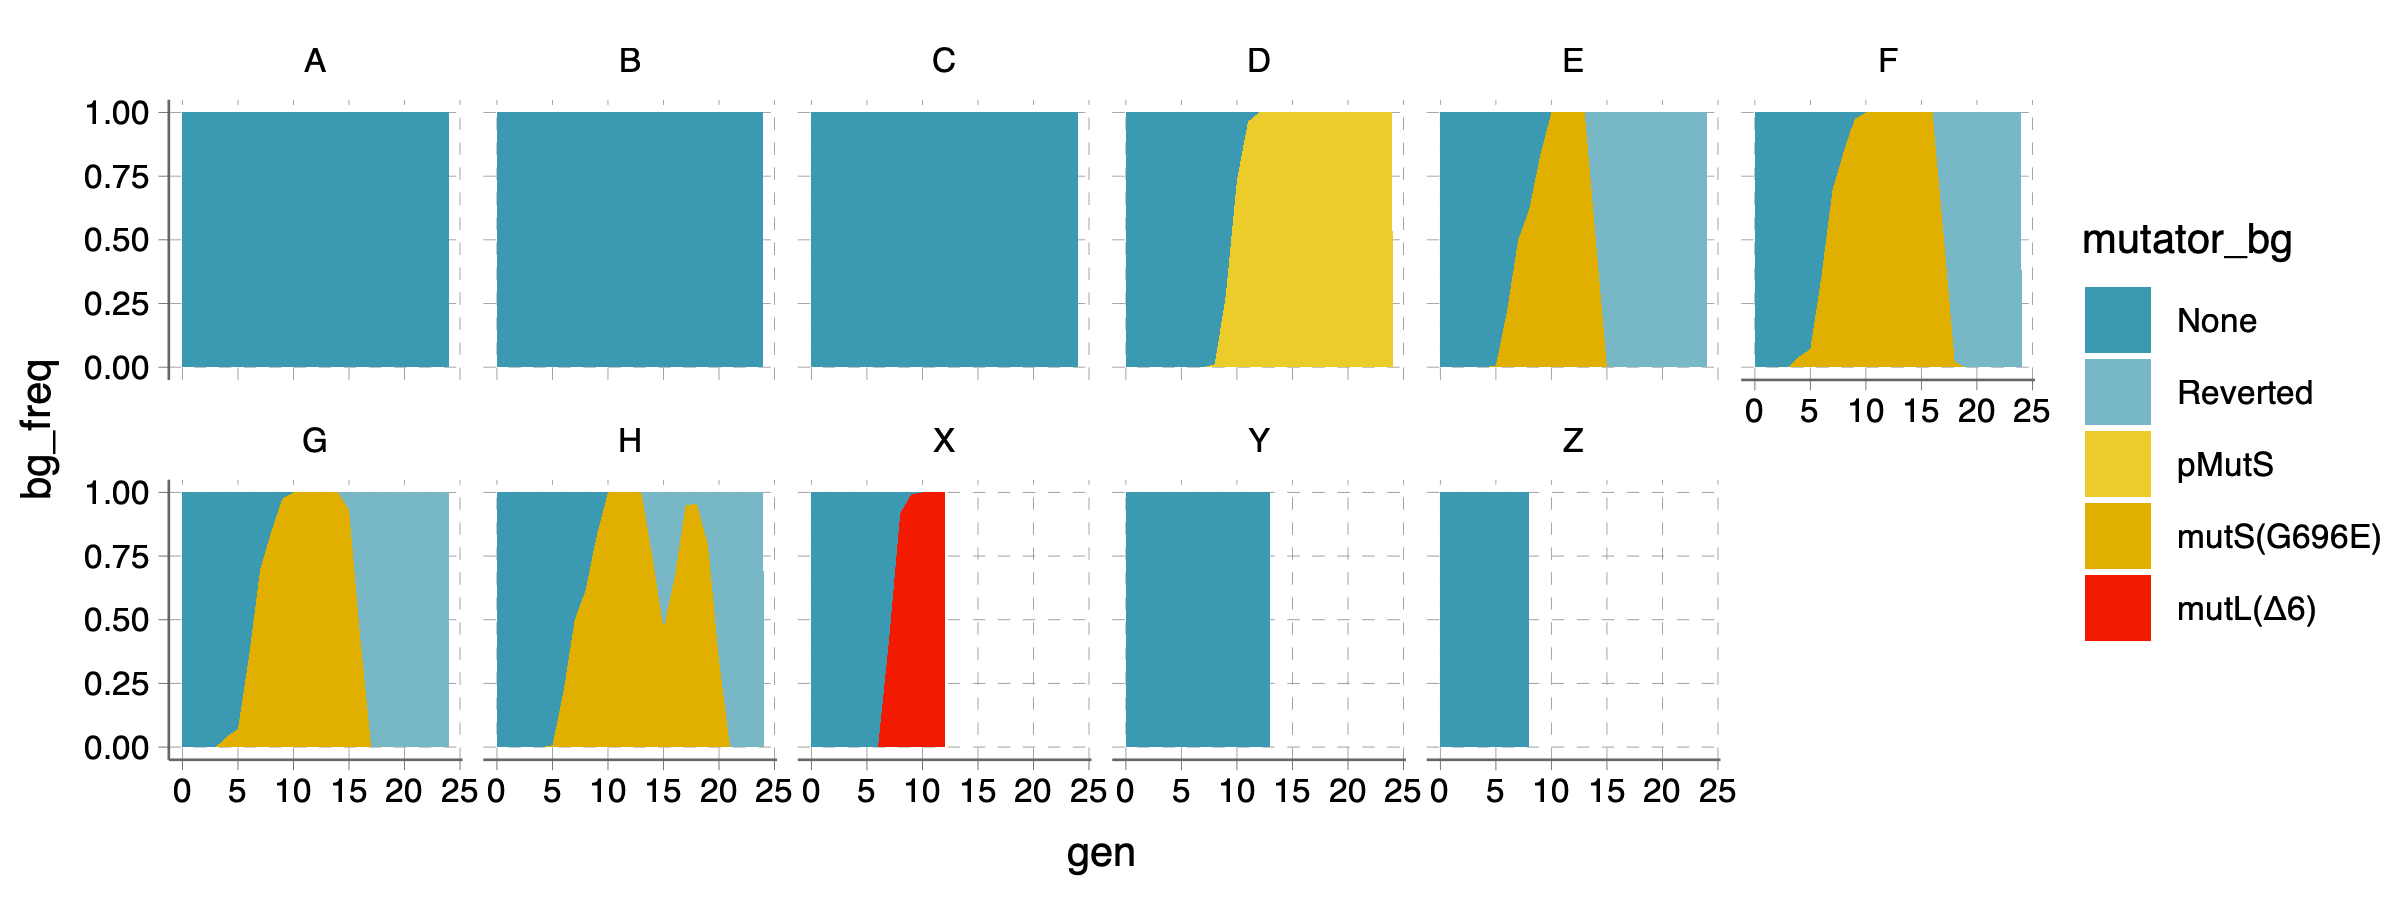

In [3]:
mut_vids = c('mutS_1', 'mutL_1', 'ygbA/mutS_1')
rev_vids = c('mutS_2')

pop_gen_mutator_to_bg_freq = 
    d %>%

    group_by(pop, gen) %>%
    summarise(
        'mutS(G696E)' = sum(freq[vid == 'mutS_1']) - sum(freq[vid == 'mutS_2']),
        'mutL(Δ6)' = sum(freq[vid == 'mutL_1']),
        'pMutS' = sum(freq[vid == 'ygbA/mutS_1']),
        'Reverted' = sum(freq[vid == 'mutS_2']),
        'None' = 1 - sum(freq[vid %in% mut_vids])
        ) %>% 
    ungroup() %>% 
    pivot_longer(cols = c('mutS(G696E)', 'mutL(Δ6)', 'Reverted', 'pMutS', 'None'), names_to = 'mutator_bg', values_to = 'current_freq') %>%

    # Use trapezoid approximation to get the average amount in the time preceding the timepoint
    arrange(pop, mutator_bg, gen) %>% 
    group_by(pop, mutator_bg) %>%
    mutate(
        bg_freq = ifelse(
            mutator_bg == 'None' & gen == 0,
            1,
            (current_freq + lag(current_freq, default = 0)) / 2
        )
    ) %>%

    # Remove combination that never occur
    group_by(pop, mutator_bg) %>%
    filter(sum(bg_freq) > 0) %>% 
    ungroup() %>% 

    # Reorder the factors
    mutate(mutator_bg = factor(mutator_bg, levels = c('None', 'Reverted', 'pMutS', 'mutS(G696E)', 'mutL(Δ6)')))

headn(pop_gen_mutator_to_bg_freq)

size(3, 8)
pop_gen_mutator_to_bg_freq %>%
    ggplot() + aes(gen, bg_freq, fill = mutator_bg) + geom_area() + facet_wrap(~pop, ncol = 6)

pop_gen_mutator_to_bg_freq %>% write.tsv('../../../datasets/genomics/06_mutators/results/pop_gen_mutator_to_bg_freq.tsv')

# Plot mutation accumulation

In [4]:
daf_lenski = 
    read.tsv('../../../datasets/genomics/06_mutators/Data_from_Good_2017/mutation_trajectories.tsv') %>% 
    mutate(gen = gen/2500) %>% 
    group_by(pop) %>%
    mutate(
        max_M = max(M),
        mutator = max_M > 500
    ) %>%
    ungroup()

daf =
d %>%
    #filter(pop %in% c('A','B','C','D','F')) %>%
    group_by(pop, gen) %>%
    summarise(
        M = sum(freq)
        ) %>% 
    group_by(pop) %>% 
    mutate(
        dM = (M - lag(M, default = 0)) / 2.5,
        ) %>%
    left_join(pop_gen_to_dominant_mutator) %>% replace_na(dominant_mutator_bg, 'None') %>% 
    filter(gen > 0) %>% 
    mutate(mutator = ifelse(grepl('mut', dominant_mutator_bg), 'Mutators', dominant_mutator_bg)) %>% 
    group_by(pop) %>% mutate(lead_mutator = lead(dominant_mutator_bg, default = 'None')) %>% ungroup() # for line color

# Add zero gen
daf = bind_rows(
    daf,
    daf %>% filter(gen==1) %>% mutate(gen=0, M=0, dM=0)
    )

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by pop and gen.
ℹ Output is grouped by pop.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(pop, gen))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


Joining with `by = join_by(pop, gen)`


In [5]:
reversions =
    daf %>%
    group_by(pop) %>%
    mutate(
        reversion = lag(lead_mutator) != 'Reverted' & lead_mutator == 'Reverted'
    ) %>%
    ungroup() %>%
    filter(reversion)

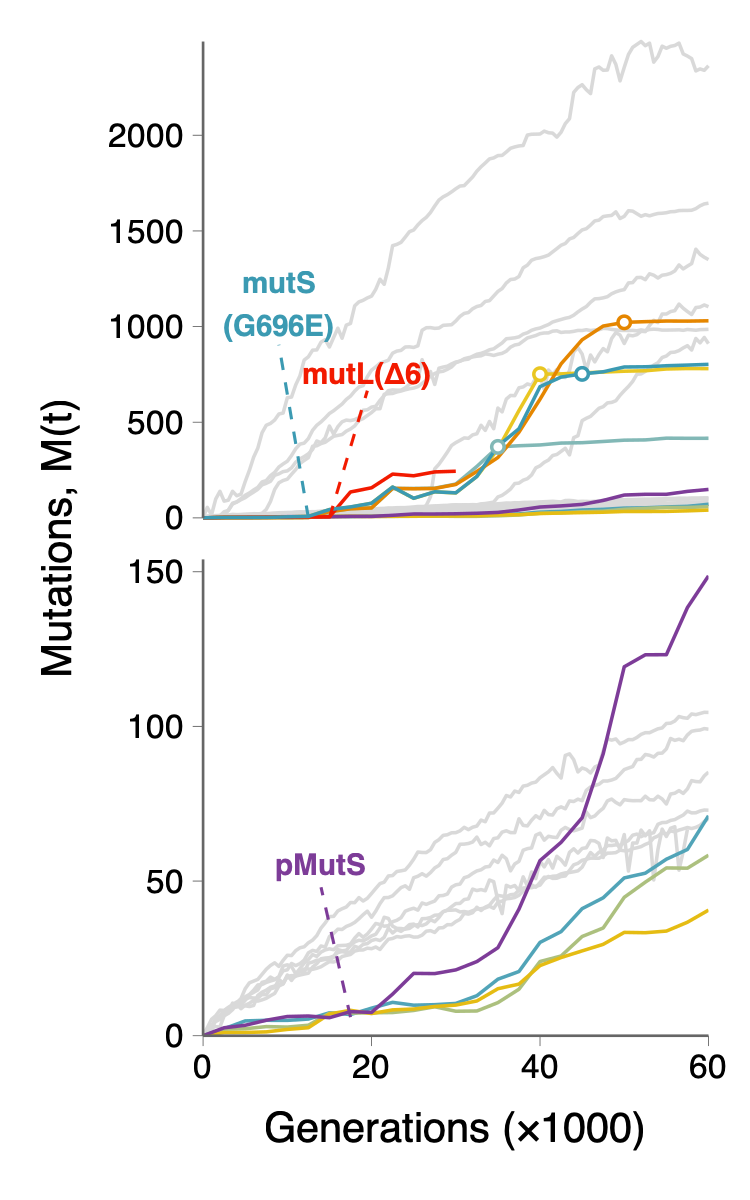

In [6]:
lwd = 0.4
lenski_color = 'grey85'

ramp = colorRampPalette(pal)(12)
purple = '#7D3C98'

pop_palette = c(
    A=ramp[2],
    B=ramp[5],
    C=ramp[8],
    D=purple,
    E=ramp[4],
    F=ramp[1], 
    G=ramp[7],
    H=ramp[10],
    X=ramp[12],
    Y='grey20',
    Z='grey20'
)

size(2.5, 2.5)

bracket_x = 60.5
bracket_xend = 61.5

daf_plot_mutators =
daf %>% 
    filter(!pop %in% c('Y','Z')) %>% 

ggplot() + aes(gen * 2.5, M, col = pop, group = fct_reorder(pop, pop=='F')) + 

    # Lenski experiment's mutators
    geom_line(
        data = daf_lenski %>% filter(gen<=24),
        col = lenski_color, lwd = 0.4
    ) +

    geom_line(lwd = lwd) +

    geom_point(
        data = reversions,
        pch = 21, size = 1, fill = w, stroke = lwd*1.5
        ) +

    # Label mutators
    add_text(3.6*2.5, 950, 'mutS\n(G696E)', size=2.5, col=pop_palette['F'], vjust=0, fontface='bold') +
    annotate(geom='segment', x=5*2.5, xend=3.6*2.5, y=0, yend=905, lwd=0.35, lty=2, col=pop_palette['F']) +

    add_text(7.8*2.5, 700, 'mutL(Δ6)', size=2.5, col=pop_palette['X'], vjust=0, fontface='bold') +
    annotate(geom='segment', x=6*2.5, xend=7.8*2.5, y=0, yend=665, lwd=0.35, lty=2, col=pop_palette['X']) +

    scale_color_manual(
        values = pop_palette
    ) +

    coord_cartesian(xlim=c(0, 60), ylim=c(0,NA), expand=c(0,0,0,0), clip='off') +
    scale_x_continuous(breaks=seq(0, 60, 20)) + small_text + small_titles +

    # Zoom label
    # annotate(
    #     geom = 'segment',
    #     x = c(bracket_x, bracket_xend, bracket_xend), xend = c(bracket_xend, bracket_xend, bracket_x),
    #     y = c(5, 5, 154), yend = c(5, 154, 154),
    #     lwd = 0.2
    # ) +

    theme(panel.grid = eb) +
    labs(x = 'Generations (×1000)', y = 'Mutations, M(t)', col = '') + nl

daf_plot_nonmutators =
daf %>%
    #filter(pop %in% c('A','B','C','D')) %>% 

ggplot() + aes(gen * 2.5, M, col = pop, group = pop) + 

    # Lenski experiment's mutators
    geom_line(
        data = daf_lenski %>% filter(!mutator, gen<=24),
        col = lenski_color, lwd = 0.4
    ) +
    # geom_line(
    #     data = daf_lenski %>% filter(mutator, gen<=24),
    #     col = lenski_color, lwd = 0.4, alpha = 0.1
    # ) +

    geom_line(
        data = daf %>% filter(pop %in% c('A','B','C','D')),
        lwd = lwd
    ) +
    # geom_line(
    #     data = daf %>% filter(!pop %in% c('A','B','C','D')),
    #     lwd = lwd, alpha = 0.1
    # ) +
    scale_color_manual(values = pop_palette) +

    # Label pMutS
    add_text(5.6*2.5, 52, 'pMutS', size=2.5, col=pop_palette['D'], vjust=0, fontface='bold') +
    annotate(geom='segment', x=7*2.5, xend=5.6*2.5, y=6, yend=48, lwd=0.35, lty=2, col=pop_palette['D']) +

    small_text + small_titles +
    theme(panel.grid = eb) +

    xcont(0, 60, breaks=seq(0, 60, 20)) + ycont(0, 154) +
    labs(x = 'Generations (×1000)', y = 'Mutations, M(t)', col = '') + nl

# Export as rds
saveRDS(daf_plot_mutators, 'Plots/GG/daf_plot_mutators.rds')
saveRDS(daf_plot_nonmutators, 'Plots/GG/daf_plot_nonmutators.rds')

size(4, 2.5)
(daf_plot_mutators + daf_plot_nonmutators) + plot_layout(ncol=1, axes='collect')

# Infer mutation rates from dM/dt

In [7]:
# Merging WT and reverted
library(broom)

size(5,7)
min_bg_freq = 0.1

mutator_to_mutation_rate =
d %>%

    # Get M per pop × gen × bg
    left_join(tid_to_mutator_bg) %>%
    mutate(mutator = ifelse(mutator_bg %in% c('None', 'Reverted'), 'Non-mutator', mutator_bg)) %>% 

    group_by(pop, gen, mutator_bg, mutator) %>%
    summarise(M = sum(freq)) %>%
    ungroup() %>% 

    # Add bg frequency
    left_join(pop_gen_mutator_to_bg_freq) %>% 
    filter(current_freq > min_bg_freq) %>% 

    # Remove cross-contam redundancies
    filter(
        !(pop == 'E' & gen <= 12),
        !(pop == 'G' & gen <= 13),
        !(pop == 'H' & gen <= 9)
    ) %>% 
    group_by(pop, mutator_bg, mutator) %>%
    filter(n() > 1) %>% 

    # Esitmate the dM/gt slope (per 1000 gen)
    mutate(rM = M / current_freq, kgen = gen*2.5) %>% 

    group_by(mutator) %>% # This is where WT and reverted are merged
    summarise(
    {
        if (n_distinct(pop, mutator_bg) > 1) { # several pops or clades (e.g. None and Reverted): same slope, one intercept per pop x clade
            tidy(lm(rM ~ kgen + interaction(pop, mutator_bg))) %>%
                filter(term == "kgen") %>%
                select(mutation_rate = estimate, mutation_rate_se = std.error)
        } else {
            tidy(lm(rM ~ kgen)) %>%
                filter(term == "kgen") %>%
                select(mutation_rate = estimate, mutation_rate_se = std.error)
        }
    },
    .groups = "drop"
    ) %>%

    # Order factors
    arrange(mutation_rate) %>% 
    mutate(mutator = fct_reorder(mutator, -mutation_rate))

mutator_to_mutation_rate %>% write.tsv('../../../datasets/genomics/06_mutators/results/mutator_to_mutation_rate.tsv')
mutator_to_mutation_rate

Joining with `by = join_by(pop, tid)`


`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by pop, gen, mutator_bg, and mutator.
ℹ Output is grouped by pop, gen, and mutator_bg.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(pop, gen, mutator_bg, mutator))` for per-operation
  grouping (`?dplyr::dplyr_by`) instead.


Joining with `by = join_by(pop, gen, mutator_bg)`


mutator,mutation_rate,mutation_rate_se
<fct>,<dbl>,<dbl>
Non-mutator,0.8865992,0.03831598
pMutS,3.8659503,0.27575771
mutL(Δ6),7.5074025,1.83621853
mutS(G696E),35.7101580,5.75228850


# Breakdown mutation spectrum

Joining with `by = join_by(ref, alt)`


`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by mutator and transition.
ℹ Output is grouped by mutator.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(mutator, transition))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


Joining with `by = join_by(mutator)`


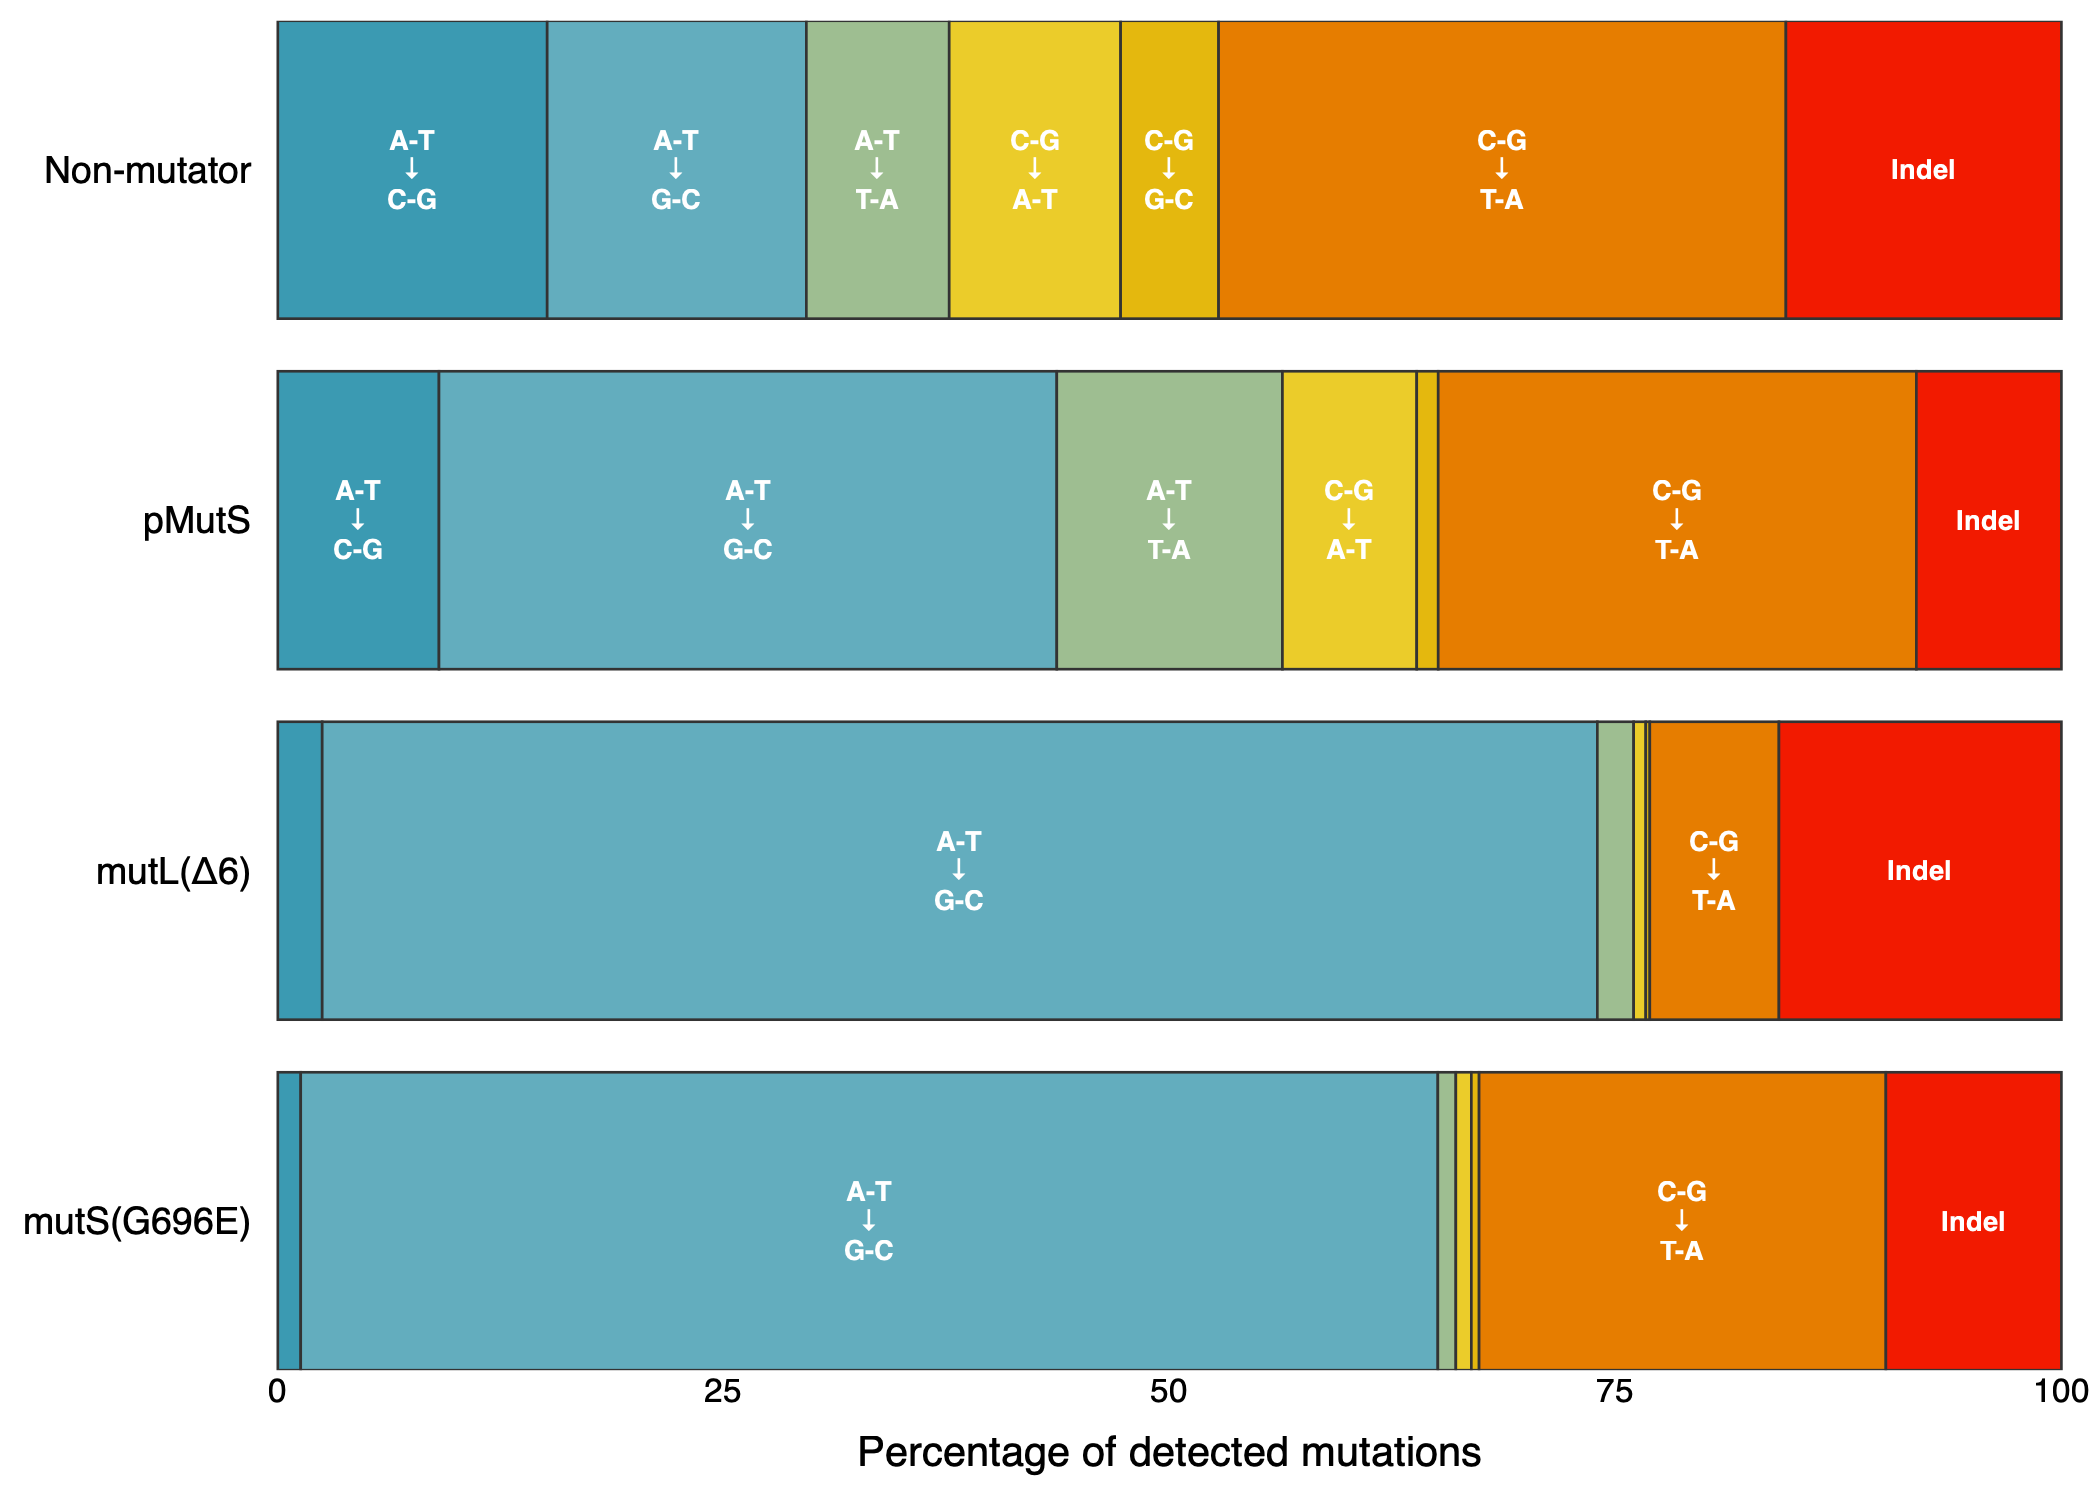

In [8]:
lwd = 0.3

v %>% 
    mutate(mutator = ifelse(mutator_bg %in% c('None', 'Reverted'), 'Non-mutator', mutator_bg)) %>% 
    left_join(ref_alt_to_nucleotide_transition) %>% replace_na(transition, 'Indel') %>% 
    group_by(mutator, transition) %>% 
    summarise(n_mut = n()) %>%
    group_by(mutator) %>% 
    mutate(f_mut = n_mut / sum(n_mut)*100) %>% 
    ungroup() %>% 
    left_join(mutator_to_mutation_rate) %>% 

    arrange(mutator, transition) %>% 
    group_by(mutator) %>%
    mutate(
        xmax = cumsum(f_mut),
        x = xmax - f_mut,
        center = (x + xmax)/2,
        width = xmax - x,
        label = gsub('→', '\n↓\n', transition)
    ) %>%
    ungroup() %>% 

ggplot() + aes(
    x = center, width = width,
    y = fct_reorder(mutator, -mutation_rate), height = 0.85,
    fill = transition,
    label=ifelse(width > 5, label, '')
    ) +

    nl +
    geom_rect(col='grey20', lwd=lwd) +
    geom_text(size = 2.3, lineheight = 0.9, fontface='bold', col=w) +

    xcont(0, 100, expand=expansion(add=1)) + scale_y_discrete(expand=expansion(add=0.2)) +

    theme(panel.grid = eb,
        axis.ticks = eb, axis.line = eb,
        legend.key.size = unit(3.5, 'mm'),
        axis.title.y = eb,
        axis.text.y = element_text(color=b, size=9),
        legend.title = eb
    ) +
    labs(x = 'Percentage of detected mutations')

psave('Plots/mutation_spectrum')